# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

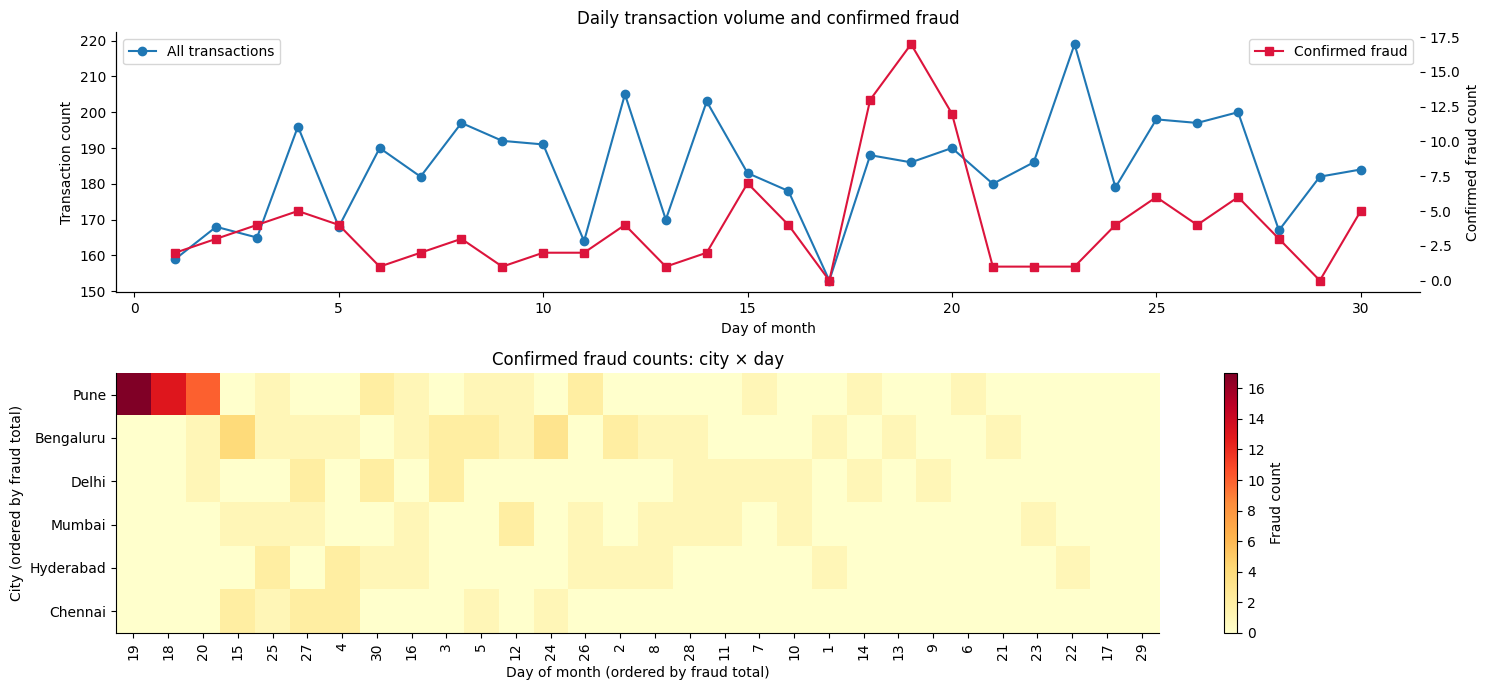

Highest-fraud city/day cells:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1
daily_all = tx.groupby("day").size()
daily_fraud = tx.groupby("day").is_fraud.sum()
axes[0].plot(daily_all.index, daily_all.values, marker="o", label="All transactions")
ax2 = axes[0].twinx()
ax2.plot(daily_fraud.index, daily_fraud.values, color="crimson", marker="s", label="Confirmed fraud")
axes[0].set(xlabel="Day of month", ylabel="Transaction count", title="Daily transaction volume and confirmed fraud")
axes[0].legend(loc="upper left"); ax2.set_ylabel("Confirmed fraud count"); ax2.legend(loc="upper right")

# TODO 2
heat = tx.pivot_table(index="city", columns="day", values="is_fraud", aggfunc="sum", fill_value=0)
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index]
heat = heat[heat.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat, aspect="auto", cmap="YlOrRd")
axes[1].set_xticks(np.arange(len(heat.columns))); axes[1].set_xticklabels(heat.columns, rotation=90)
axes[1].set_yticks(np.arange(len(heat.index))); axes[1].set_yticklabels(heat.index)
axes[1].set(xlabel="Day of month (ordered by fraud total)", ylabel="City (ordered by fraud total)",
            title="Confirmed fraud counts: city × day")
fig.colorbar(im, ax=axes[1], label="Fraud count")

plt.tight_layout(); plt.show()

# TODO 3
top_cells = tx.groupby(["city", "day"]).is_fraud.sum().sort_values(ascending=False).head(5)
print("Highest-fraud city/day cells:")
print(top_cells.to_string())


**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

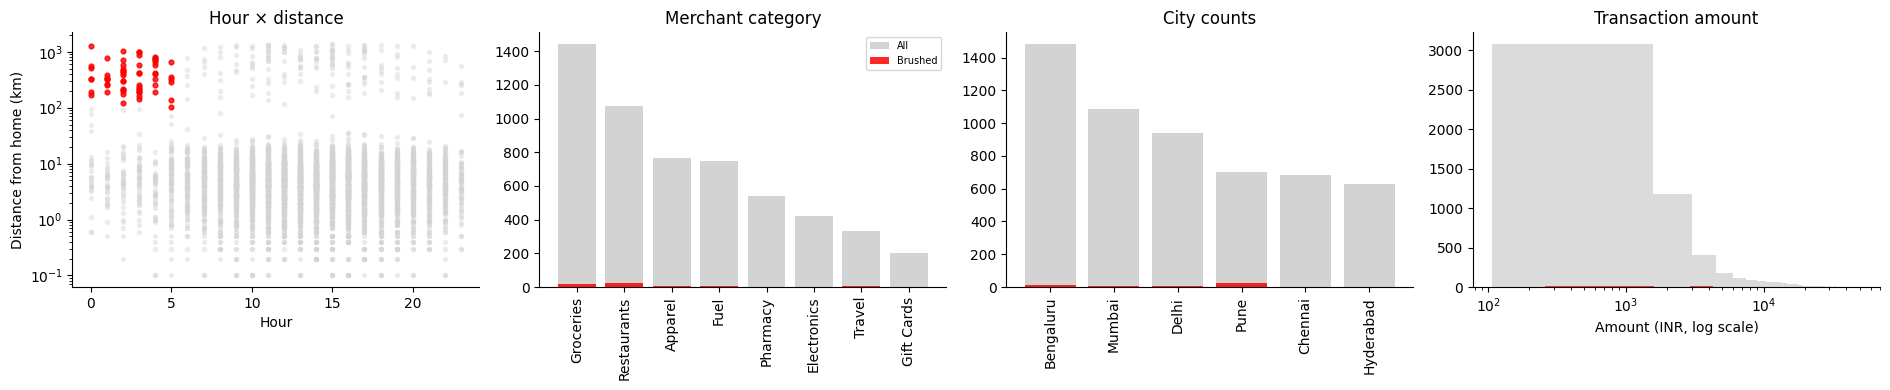

Brushed: 61 transactions | fraud rate inside: 86.89% | overall: 2.17% | share of all fraud captured: 44.17%


In [3]:
# TODO 1
brush = tx["night"] & (tx["distance_from_home_km"] > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
axes[0].scatter(tx.hour, tx.distance_from_home_km, c="lightgray", s=8, alpha=0.35)
axes[0].scatter(tx.loc[brush, "hour"], tx.loc[brush, "distance_from_home_km"], c="red", s=12, alpha=0.8)
axes[0].set_yscale("log"); axes[0].set(xlabel="Hour", ylabel="Distance from home (km)", title="Hour × distance")

cat_all = tx.merchant_category.value_counts()
cat_brush = tx.loc[brush, "merchant_category"].value_counts()
axes[1].bar(cat_all.index, cat_all.values, color="lightgray", label="All")
axes[1].bar(cat_brush.index, cat_brush.reindex(cat_all.index, fill_value=0).values, color="red", alpha=0.85, label="Brushed")
axes[1].tick_params(axis="x", rotation=90); axes[1].set_title("Merchant category"); axes[1].legend(fontsize=7)

city_all = tx.city.value_counts()
city_brush = tx.loc[brush, "city"].value_counts()
axes[2].bar(city_all.index, city_all.values, color="lightgray")
axes[2].bar(city_all.index, city_brush.reindex(city_all.index, fill_value=0).values, color="red", alpha=0.85)
axes[2].tick_params(axis="x", rotation=90); axes[2].set_title("City counts")

axes[3].hist(tx.amount_inr, bins=35, color="lightgray", alpha=0.8)
axes[3].hist(tx.loc[brush, "amount_inr"], bins=35, color="red", alpha=0.75)
axes[3].set_xscale("log"); axes[3].set(xlabel="Amount (INR, log scale)", title="Transaction amount")

plt.tight_layout(); plt.show()

# TODO 3
n_brush = int(brush.sum())
fraud_rate_brush = tx.loc[brush, "is_fraud"].mean()
fraud_rate_overall = tx.is_fraud.mean()
fraud_capture_share = tx.loc[brush, "is_fraud"].sum() / tx.is_fraud.sum()
print(f"Brushed: {n_brush:,} transactions | fraud rate inside: {fraud_rate_brush:.2%} | overall: {fraud_rate_overall:.2%} | share of all fraud captured: {fraud_capture_share:.2%}")


**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1
filter_expr = lambda frame: (frame.detector_score >= 0.6) & (frame.amount_inr > 3000)
timings = []
for _ in range(5):
    start = time.perf_counter()
    _ = filter_expr(big)
    timings.append(time.perf_counter() - start)
best_s = min(timings)

# TODO 2
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (best_s / len(big))

# TODO 3
t_50m = per_item_us * 50_000_000 / 1e6
skip_pct = max(0.0, (1 - 0.1 / t_50m) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")


1,004,640 rows in 2.8 ms -> 0.0028 us/row -> max 35,931,356 rows in 0.1 s
50M rows -> 0.14 s; must skip 28.1% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

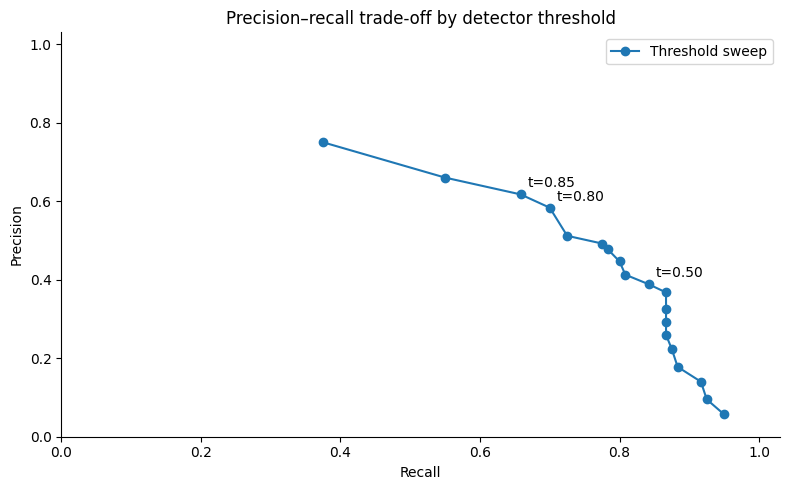

Recommendation: use threshold 0.80 (144 alerts; precision 58.3%, recall 70.0%) to stay within the 150-alert monthly review capacity.


In [5]:
rows = []
# TODO 1
y = tx.is_fraud.to_numpy()
for threshold in np.arange(0.05, 1.0, 0.05):
    pred = tx.detector_score.to_numpy() >= threshold
    tp = int(np.sum(pred & (y == 1)))
    fp = int(np.sum(pred & (y == 0)))
    fn = int(np.sum((~pred) & (y == 1)))
    alerts = int(pred.sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    rows.append({"threshold": round(float(threshold), 2), "alerts": alerts, "TP": tp, "FP": fp, "FN": fn,
                 "precision": precision, "recall": recall, "F1": f1})

pr = pd.DataFrame(rows)

# TODO 2
eligible = pr[pr.alerts <= 150]
capacity_choice = eligible.sort_values(["recall", "precision"], ascending=False).iloc[0]
best_f1 = pr.loc[pr.F1.idxmax()]

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, marker="o", label="Threshold sweep")
for r in [pr.iloc[(pr.threshold - 0.5).abs().argmin()], capacity_choice, best_f1]:
    ax.annotate(f"t={r.threshold:.2f}", (r.recall, r.precision), xytext=(5, 5), textcoords="offset points")
ax.set(xlabel="Recall", ylabel="Precision", title="Precision–recall trade-off by detector threshold")
ax.set_xlim(0, 1.03); ax.set_ylim(0, 1.03); ax.legend()

plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommendation: use threshold {capacity_choice.threshold:.2f} ({int(capacity_choice.alerts)} alerts; precision {capacity_choice.precision:.1%}, recall {capacity_choice.recall:.1%}) to stay within the 150-alert monthly review capacity.")


**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1
flagged = tx[tx.detector_score >= 0.3].copy()

fig_scatter = px.scatter(
    flagged, x="timestamp", y="amount_inr", color="label",
    hover_data=["txn_id", "customer_id", "city", "merchant_category", "distance_from_home_km", "detector_score"],
    log_y=True, title="Flagged transactions (detector score ≥ 0.3)"
)
fig_scatter.update_layout(dragmode="select")
fig_scatter.show()

# TODO 2
sun = tx.groupby(["city", "merchant_category"], as_index=False).agg(
    transactions=("txn_id", "count"), frauds=("is_fraud", "sum")
)
sun["fraud_rate"] = sun["frauds"] / sun["transactions"]
fig_sun = px.sunburst(sun, path=["city", "merchant_category"], values="transactions",
                      color="fraud_rate", color_continuous_scale="Reds",
                      title="Transaction drill-down: city → merchant category (colour = fraud rate)")
fig_sun.show()


**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

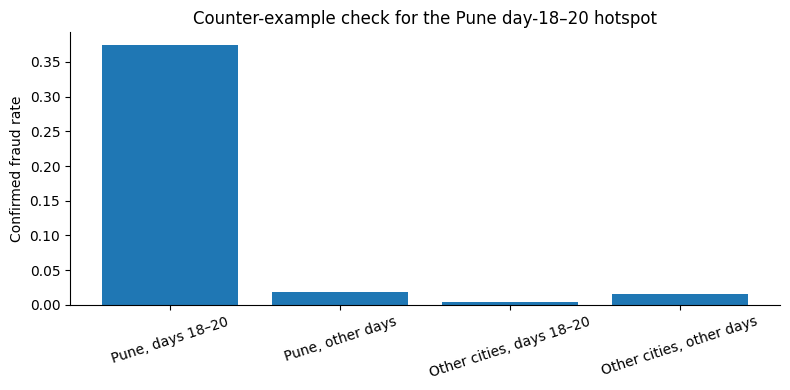

Pune days 18–20 fraud rate: 37.38%; outside: 1.48%; chi-square p=1.06e-136.
Counter-example rates: {'Pune, days 18–20': '37.38%', 'Pune, other days': '1.85%', 'Other cities, days 18–20': '0.44%', 'Other cities, other days': '1.54%'}
Verdict: the Pune day-18–20 cluster is statistically elevated in this sample, but it is not proof of a coordinated fraud ring; investigate shared customers/merchants and operational causes.


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
# The strongest city/day hotspot in the overview is Pune on days 18–20.
in_window = tx.city.eq("Pune") & tx.day.between(18, 20)

# TODO 2
inside_rate = tx.loc[in_window, "is_fraud"].mean()
outside_rate = tx.loc[~in_window, "is_fraud"].mean()
contingency = pd.crosstab(in_window, tx.is_fraud)
chi2, p_value, dof, expected = chi2_contingency(contingency)

# TODO 3
same_city_other_days = tx.city.eq("Pune") & ~tx.day.between(18, 20)
other_cities_same_days = ~tx.city.eq("Pune") & tx.day.between(18, 20)
rest = ~in_window & ~same_city_other_days & ~other_cities_same_days
groups = {
    "Pune, days 18–20": in_window,
    "Pune, other days": same_city_other_days,
    "Other cities, days 18–20": other_cities_same_days,
    "Other cities, other days": rest
}
rates = {name: float(tx.loc[mask, "is_fraud"].mean()) for name, mask in groups.items()}

# TODO 4
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(list(rates.keys()), list(rates.values()))
ax.set_ylabel("Confirmed fraud rate")
ax.set_title("Counter-example check for the Pune day-18–20 hotspot")
ax.tick_params(axis="x", rotation=18)

plt.tight_layout(); plt.show()

# TODO 5
print(f"Pune days 18–20 fraud rate: {inside_rate:.2%}; outside: {outside_rate:.2%}; chi-square p={p_value:.3g}.")
print("Counter-example rates:", {k: f"{v:.2%}" for k, v in rates.items()})
if p_value < 0.05 and inside_rate > outside_rate:
    print("Verdict: the Pune day-18–20 cluster is statistically elevated in this sample, but it is not proof of a coordinated fraud ring; investigate shared customers/merchants and operational causes.")
else:
    print("Verdict: the available data do not establish a statistically elevated Pune day-18–20 cluster; do not claim a fraud ring.")


**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

The overview identifies a concentrated spike in confirmed fraud in Pune on days 18–20, with the strongest single city/day cell on day 19; this is a lead for investigation, not proof of a criminal ring. I recommend threshold **0.80**, which produces **144 alerts**, within the 150-case review capacity, while retaining **70.0% recall** at **58.3% precision**. The first investigator tool should be the interactive flagged-transaction scatter because selection, zoom and hover details support details-on-demand and drill-down. The 50-million-row estimate shows that a raw slider query needs indexing or pre-aggregation to meet the 0.1-second dynamic-query budget. Finally, close the human-in-the-loop feedback loop by collecting investigator dispositions, reviewing false positives and missed fraud, and using those labelled outcomes to retrain and recalibrate the detector.